# Machine Learning Laboratory · 02
## Networks, automatic differentiation and optimisation

Experiments for **slides L2-S15–L2-S60**. This notebook is self-contained:
run it in a fresh kernel; no earlier notebook or saved result is required.

[All notebooks and setup](NOTEBOOK_README.md) · [Practical exercises](exercises/README.md)

Install `requirements-notebook.txt`, then select **Restart Kernel and Run All Cells**.
Saved static plots are visible on GitHub. Python 3.11+; CPU / float64.

**Question:** how do representation, differentiation and optimisation contribute
different sources of error to the same regression problem?

In [1]:
import copy, io, json, platform, time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display, Image

SEED = 4
RUN_MODE = "quick"                 # "quick" or "thorough"
assert RUN_MODE in {"quick", "thorough"}
FACTOR = 1 if RUN_MODE == "quick" else 2
START = time.perf_counter()
torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
versions = dict(python=platform.python_version(), numpy=np.__version__,
                matplotlib=matplotlib.__version__, torch=torch.__version__)
print(json.dumps(versions, indent=2))
print(f"CPU / float64 / seed {SEED} / {RUN_MODE} mode")

palette = {"navy": "#10243A", "teal": "#00A6A6", "orange": "#F28C45",
           "pink": "#DC4778", "blue": "#4878D0", "ink": "#183449", "muted": "#63788A"}
plt.rcParams.update({
    "figure.facecolor": "#F7FAFC", "axes.facecolor": "#F7FAFC",
    "axes.edgecolor": "#CAD6DF", "axes.labelcolor": palette["ink"],
    "text.color": palette["ink"], "xtick.color": palette["muted"],
    "ytick.color": palette["muted"], "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#DCE5EB", "grid.alpha": 0.65,
    "lines.linewidth": 2.3, "figure.dpi": 110, "legend.frameon": False,
    "font.family": "DejaVu Sans",
    "axes.prop_cycle": matplotlib.cycler(color=[palette[k] for k in
                                      ["teal", "orange", "pink", "blue", "navy"]]),
})

def show_figure(fig):
    """Embed a compact static PNG so GitHub can display the result."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=120, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

def signal(x):
    return np.sin(np.pi*x)

def sample_data(generator, n, sigma=0.05):
    x = np.sort(generator.uniform(0, 1, n))[:, None]
    y = signal(x) + sigma*generator.normal(size=x.shape)
    return x, y

def make_mlp(width=16, depth=2):
    layers = [nn.Linear(1, width), nn.Tanh()]
    for _ in range(depth-1):
        layers += [nn.Linear(width, width), nn.Tanh()]
    return nn.Sequential(*layers, nn.Linear(width, 1))

{
  "python": "3.13.9",
  "numpy": "2.4.2",
  "matplotlib": "3.10.8",
  "torch": "2.10.0"
}
CPU / float64 / seed 4 / quick mode


## 1 · Construct a ReLU approximant before training anything

For knots $0=t_0<\cdots<t_m=1$ and slopes
$s_i=(f_\star(t_{i+1})-f_\star(t_i))/(t_{i+1}-t_i)$, linear interpolation is
$$u(x)=f_\star(0)+s_0x+\sum_{i=1}^{m-1}(s_i-s_{i-1})\max(0,x-t_i).$$
On $[0,1]$, $x=\operatorname{ReLU}(x)$, so this is a one-hidden-layer network
with $m$ units. We set its weights explicitly. For this smooth target, uniform
linear interpolation has $O(m^{-2})$ maximum error.

This construction illustrates an approximation mechanism in one dimension.
It is neither a proof of the general universal approximation theorem nor a claim
that a training algorithm will discover these weights from noisy data.

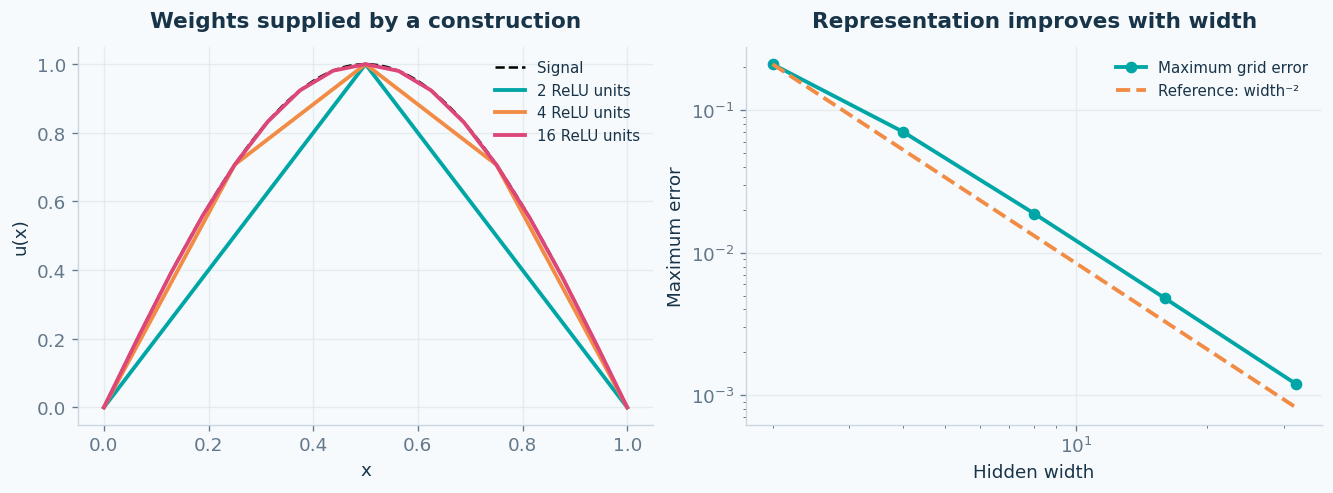

Maximum grid errors: {2: np.float64(0.2105132), 4: np.float64(0.070377), 8: np.float64(0.0188463), 16: np.float64(0.0047919), 32: np.float64(0.0012024)}


In [2]:
def relu_interpolant(intervals):
    knots = np.linspace(0, 1, intervals+1)
    values = signal(knots)
    slopes = np.diff(values)/np.diff(knots)
    model = nn.Sequential(nn.Linear(1, intervals), nn.ReLU(), nn.Linear(intervals, 1))
    with torch.no_grad():
        model[0].weight.fill_(1)
        model[0].bias.copy_(torch.tensor(-knots[:-1]))
        model[2].weight.copy_(torch.tensor(np.r_[slopes[0], np.diff(slopes)][None, :]))
        model[2].bias.fill_(values[0])
    with torch.no_grad():
        knot_error = np.max(np.abs(model(torch.tensor(knots[:, None])).numpy()[:, 0]-values))
    assert knot_error < 1e-12
    return model

xgrid = np.linspace(0, 1, 1001)
tgrid = torch.tensor(xgrid[:, None])
widths = [2, 4, 8, 16, 32]
max_errors = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].plot(xgrid, signal(xgrid), "k--", lw=1.5, label="Signal")
for width in widths:
    model = relu_interpolant(width)
    with torch.no_grad():
        prediction = model(tgrid).numpy()[:, 0]
    max_errors.append(np.max(np.abs(prediction-signal(xgrid))))
    if width in [2, 4, 16]:
        axes[0].plot(xgrid, prediction, label=f"{width} ReLU units")
axes[0].set(title="Weights supplied by a construction", xlabel="x", ylabel="u(x)")
axes[1].loglog(widths, max_errors, "o-", label="Maximum grid error")
axes[1].loglog(widths, max_errors[0]*(np.array(widths)/widths[0])**-2., "--", label="Reference: width⁻²")
axes[1].set(title="Representation improves with width", xlabel="Hidden width", ylabel="Maximum error")
for ax in axes:
    ax.legend(fontsize=9); ax.grid()
show_figure(fig)
print("Maximum grid errors:", dict(zip(widths, np.round(max_errors, 7))))

## 2 · Check shapes and gradients before training

For an affine predictor, the empirical gradient is
$\nabla L(\beta)=2A^T(A\beta-y)/N$.
We compare that expression with PyTorch reverse-mode differentiation and a
central finite difference. Finite differences are a diagnostic, not the training method.

Keep predictions and labels both `(N, 1)`: subtracting a label tensor `(N,)`
from predictions `(N, 1)` silently creates `(N, N)` pairwise differences.
PyTorch stores each linear-layer weight as `(out_features, in_features)`,
which is the transpose of the row-sample convention used in the slides.

In [3]:
train_x, train_y = sample_data(rng, 64)
X, Y = torch.tensor(train_x), torch.tensor(train_y)
A = np.column_stack([train_x[:, 0], np.ones(len(train_x))])
beta = torch.tensor([0.3, -0.2], requires_grad=True)
prediction = beta[0]*X + beta[1]
assert prediction.shape == Y.shape == (64, 1)
loss = (prediction-Y).square().mean()
loss.backward()
auto_gradient = beta.grad.detach().numpy().copy()
point = beta.detach().numpy()
manual_gradient = 2*A.T @ (A @ point-train_y[:, 0])/len(A)
def affine_loss(b):
    return np.mean((A @ b-train_y[:, 0])**2)
h = 1e-6
finite_difference = np.array([(affine_loss(point+h*e)-affine_loss(point-h*e))/(2*h)
                              for e in np.eye(2)])
assert np.allclose(auto_gradient, manual_gradient, atol=1e-12)
assert np.allclose(auto_gradient, finite_difference, atol=1e-8)
print("Autograd:          ", auto_gradient)
print("Analytic gradient: ", manual_gradient)
print("Finite differences:", finite_difference)
print("Shape trap:", tuple((prediction-Y[:, 0]).shape), "instead of", tuple((prediction-Y).shape))
shape_model = make_mlp(width=32, depth=2)
parameter_count = sum(p.numel() for p in shape_model.parameters())
assert parameter_count == (1*32+32)+(32*32+32)+(32*1+1) == 1153
print("1 → 32 → 32 → 1 parameters:", parameter_count)

Autograd:           [-0.64446483 -1.34519597]
Analytic gradient:  [-0.64446483 -1.34519597]
Finite differences: [-0.64446483 -1.34519597]
Shape trap: (64, 64) instead of (64, 1)
1 → 32 → 32 → 1 parameters: 1153


## 3 · A quadratic reveals the learning-rate limit

The affine objective has Hessian $H=2A^TA/N$. If $L$ is its largest eigenvalue,
constant-step gradient descent converges for $0<\eta<2/L$ when $H$ is positive
definite. This is a statement about this quadratic; it does not automatically apply
to a nonlinear network. We use the least-squares minimum to measure optimisation error.

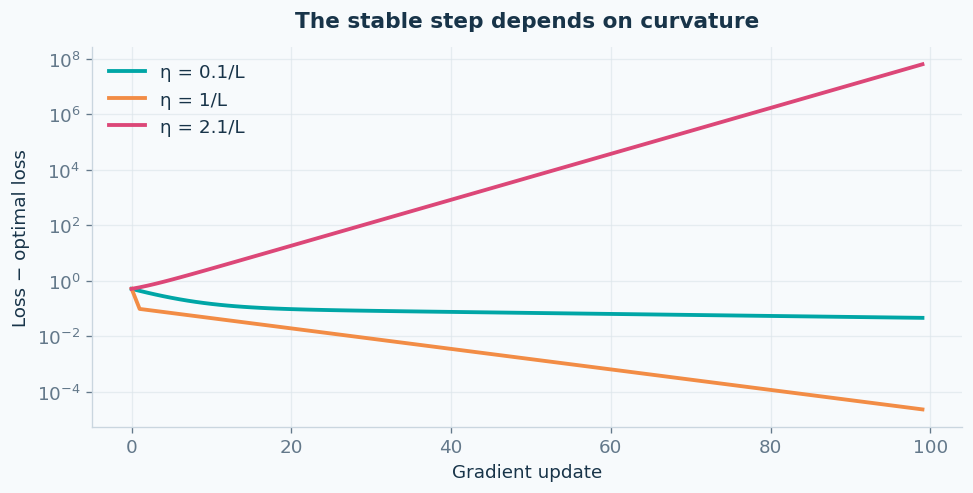

Largest Hessian eigenvalue L = 2.71015; stability limit 2/L = 0.73797


In [4]:
H = 2*A.T @ A/len(A)
L = np.linalg.eigvalsh(H).max()
beta_star, *_ = np.linalg.lstsq(A, train_y[:, 0], rcond=None)
minimum_loss = affine_loss(beta_star)
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for multiplier in [.1, 1., 2.1]:
    eta = multiplier/L
    b = np.array([.3, -.2])
    excess = []
    for step in range(100):
        excess.append(max(affine_loss(b)-minimum_loss, 1e-16))
        b -= eta*(2*A.T @ (A @ b-train_y[:, 0])/len(A))
    ax.semilogy(excess, label=f"η = {multiplier:g}/L")
    assert np.all(np.isfinite(excess))
ax.set(title="The stable step depends on curvature", xlabel="Gradient update", ylabel="Loss − optimal loss")
ax.legend(); ax.grid()
show_figure(fig)
print(f"Largest Hessian eigenvalue L = {L:.5f}; stability limit 2/L = {2/L:.5f}")

## 4 · Train a nonlinear network from the same initial state

Compare full-batch momentum SGD and Adam on the same noisy dataset. We reset
both methods to the same initial parameters, use fixed learning rates and budgets,
and monitor a separate validation sample. The settings are illustrative, so these
curves do not establish that either optimiser is universally better.

The five training steps are: clear gradients, predict, compute the loss, backpropagate,
and update parameters. `eval()` controls layer behaviour; `no_grad()` disables gradient
recording. They serve different purposes even though this MLP has no dropout or batch normalisation.

Momentum SGD  | updates 700 | parameters 321 | train 0.00273 | validation 0.00440


Adam          | updates 700 | parameters 321 | train 0.00228 | validation 0.00302


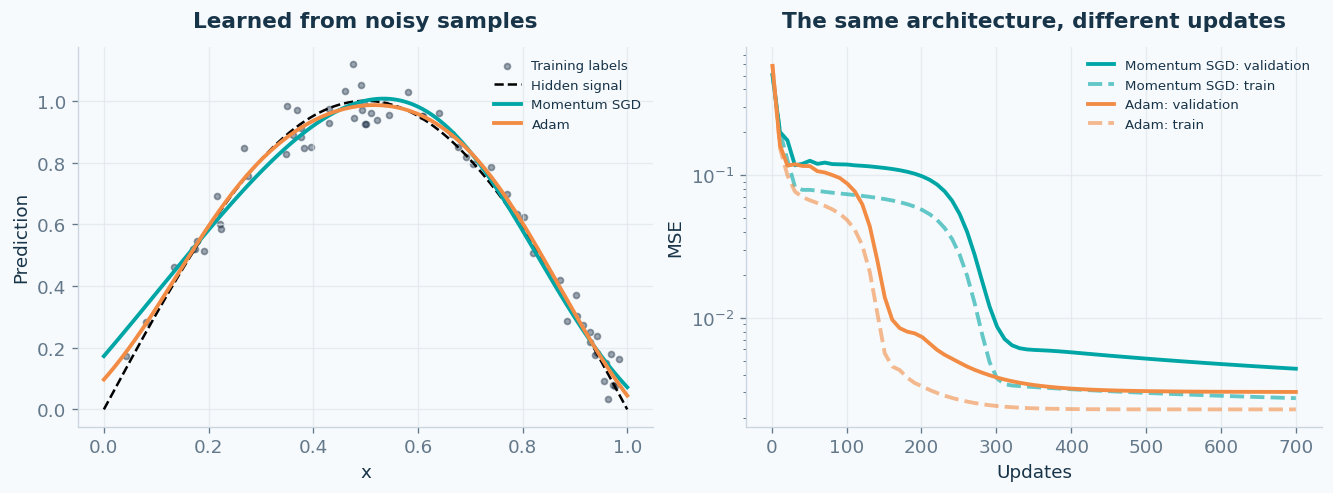

Notebook runtime: 2.1 s


In [5]:
validation_x, validation_y = sample_data(np.random.default_rng(SEED+1), 128)
VX, VY = torch.tensor(validation_x), torch.tensor(validation_y)
torch.manual_seed(SEED)
initial = make_mlp(width=16, depth=2)
steps = 700*FACTOR
trained, histories = {}, {}
for name in ["Momentum SGD", "Adam"]:
    model = copy.deepcopy(initial)
    optimizer = (torch.optim.SGD(model.parameters(), lr=.04, momentum=.9)
                 if name == "Momentum SGD" else torch.optim.Adam(model.parameters(), lr=.01))
    history = []
    for step in range(steps):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        prediction = model(X)
        assert prediction.shape == Y.shape
        objective = (prediction-Y).square().mean()
        objective.backward()
        optimizer.step()
        if step % 10 == 0 or step == steps-1:
            model.eval()
            with torch.no_grad():
                history.append((step+1, (model(X)-Y).square().mean().item(),
                                (model(VX)-VY).square().mean().item()))
    trained[name], histories[name] = model, np.array(history)
    assert np.isfinite(history[-1][2])
    print(f"{name:13s} | updates {steps} | parameters {sum(p.numel() for p in model.parameters())}"
          f" | train {history[-1][1]:.5f} | validation {history[-1][2]:.5f}")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].scatter(train_x, train_y, s=13, color=palette["navy"], alpha=.4, label="Training labels")
axes[0].plot(xgrid, signal(xgrid), "k--", lw=1.5, label="Hidden signal")
for name, model in trained.items():
    with torch.no_grad():
        axes[0].plot(xgrid, model(tgrid).numpy()[:, 0], label=name)
    history = histories[name]
    line, = axes[1].semilogy(history[:, 0], history[:, 2], label=f"{name}: validation")
    axes[1].semilogy(history[:, 0], history[:, 1], "--", color=line.get_color(), alpha=.6,
                     label=f"{name}: train")
axes[0].set(title="Learned from noisy samples", xlabel="x", ylabel="Prediction")
axes[1].set(title="The same architecture, different updates", xlabel="Updates", ylabel="MSE")
for ax in axes:
    ax.legend(fontsize=8); ax.grid()
show_figure(fig)
print(f"Notebook runtime: {time.perf_counter()-START:.1f} s")

## Read the evidence

Construction, gradient accuracy and training progress answer different questions.
The ReLU example controls approximation error with known signal values; the trained
MLP must also cope with noisy observations and finite optimisation time.

**Try:** change the activation to ReLU, compare widths, or add mini-batching while
recording both epochs and gradient updates. Change one factor at a time. Explain why
an approximation theorem supplies neither a learning rate nor a sample-size guarantee.

Continue with [regularisation and model selection](ML_03_regularisation_and_selection.ipynb),
or work through [practical 02](exercises/ML_Exercises_02_autograd_and_optimisation.ipynb).